# Monthly economic news tone indices

This notebook reads the combined economic-data workbook and plots the unsmoothed T5 and DeepSeek monthly tone indices. The plotted values are the saved monthly indices; no model inference or relabeling is performed.

Required packages: `pandas`, `openpyxl`, and `matplotlib`.

In [1]:
from pathlib import Path

import matplotlib.dates as mdates
import matplotlib.pyplot as plt
import pandas as pd

candidate_roots = [Path.cwd(), Path.cwd().parent]
project_root = next(
    root for root in candidate_roots
    if (root / 'outputs' / 'monthly_tone_index').exists()
)
workbook_path = (
    project_root
    / 'outputs'
    / 'monthly_tone_index'
    / 'Consumer_Sentiment_Economic_Data_2010_2026_with_tone_indices.xlsx'
)
figure_path = project_root / 'outputs' / 'monthly_tone_index' / 'tone_indices_from_notebook.png'
workbook_path

WindowsPath('c:/Users/Jerry Cai/Desktop/NLP_Final_Assignment/outputs/monthly_tone_index/Consumer_Sentiment_Economic_Data_2010_2026_with_tone_indices.xlsx')

In [2]:
monthly = pd.read_excel(workbook_path, sheet_name='Monthly')
required = {'month', 'news_tone_index_t5', 'news_tone_index_deepseek'}
missing = required.difference(monthly.columns)
if missing:
    raise KeyError(f'Missing required columns: {sorted(missing)}')

monthly['month'] = pd.to_datetime(monthly['month'], errors='raise')
monthly = monthly.sort_values('month').reset_index(drop=True)
index_columns = ['news_tone_index_t5', 'news_tone_index_deepseek']
monthly[index_columns] = monthly[index_columns].apply(
    pd.to_numeric, errors='raise'
)
print(f"Months: {monthly['month'].min():%Y-%m} to {monthly['month'].max():%Y-%m}")
print(f"Rows: {len(monthly):,}")
monthly[['month', 'news_tone_index_t5', 'news_tone_index_deepseek']].head()

Months: 2010-01 to 2026-10
Rows: 202


,month,news_tone_index_t5,news_tone_index_deepseek
0,2010-01-01 00:00:00+00:00,-22.624434,-36.000000
1,2010-02-01 00:00:00+00:00,-25.000000,-25.543478
2,2010-03-01 00:00:00+00:00,-17.647059,-16.826923
3,2010-04-01 00:00:00+00:00,-1.212121,-12.987013
4,2010-05-01 00:00:00+00:00,-12.328767,-23.357664


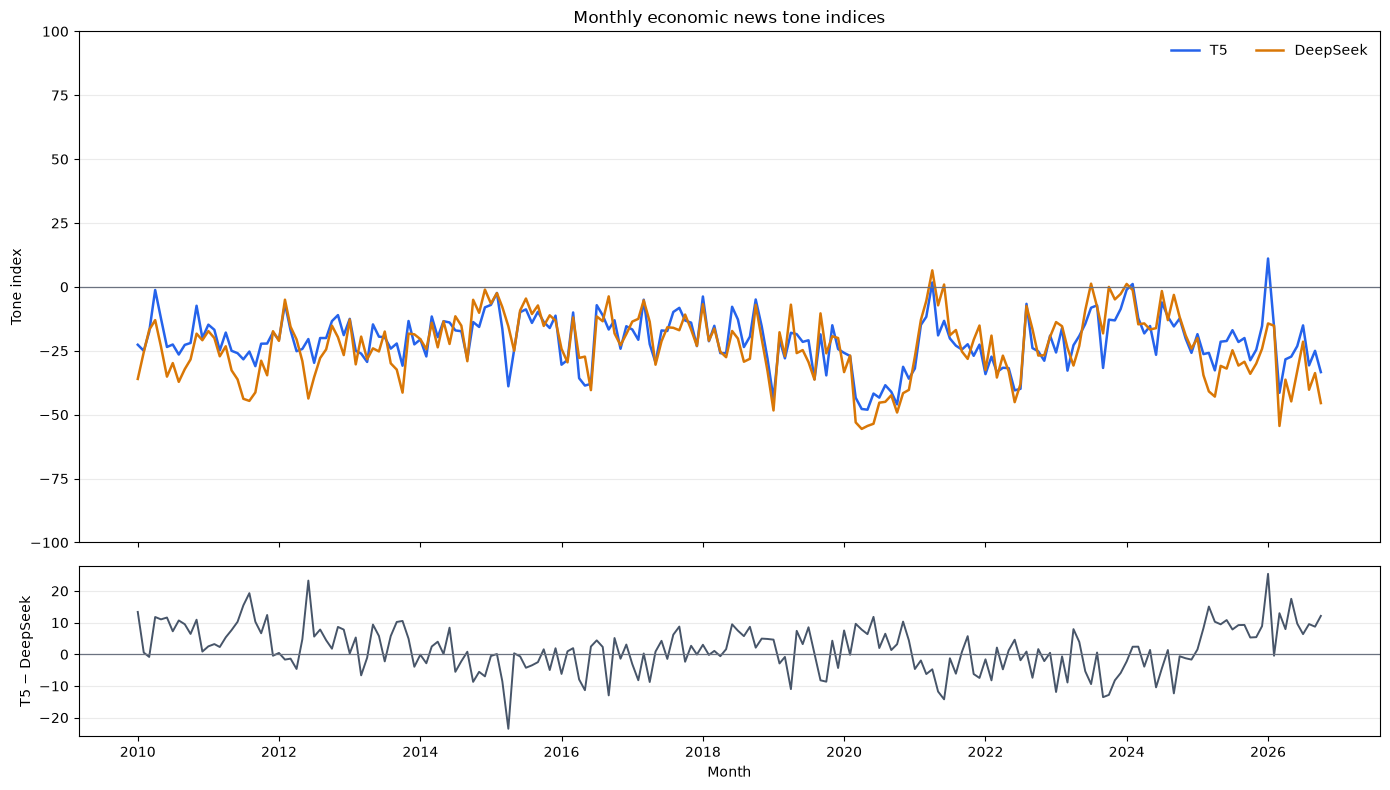

WindowsPath('c:/Users/Jerry Cai/Desktop/NLP_Final_Assignment/outputs/monthly_tone_index/tone_indices_from_notebook.png')

In [3]:
difference = monthly['news_tone_index_t5'] - monthly['news_tone_index_deepseek']

fig, (ax_index, ax_diff) = plt.subplots(
    2, 1, figsize=(14, 8), sharex=True,
    gridspec_kw={'height_ratios': [3, 1]},
)

ax_index.plot(
    monthly['month'], monthly['news_tone_index_t5'],
    color='#2563EB', linewidth=1.8, label='T5',
)
ax_index.plot(
    monthly['month'], monthly['news_tone_index_deepseek'],
    color='#D97706', linewidth=1.8, label='DeepSeek',
)
ax_index.axhline(0, color='#6B7280', linewidth=0.9)
ax_index.set_title('Monthly economic news tone indices')
ax_index.set_ylabel('Tone index')
ax_index.set_ylim(-100, 100)
ax_index.legend(frameon=False, ncol=2)
ax_index.grid(axis='y', alpha=0.25)

ax_diff.plot(monthly['month'], difference, color='#475569', linewidth=1.4)
ax_diff.axhline(0, color='#6B7280', linewidth=0.9)
ax_diff.set_ylabel('T5 − DeepSeek')
ax_diff.set_xlabel('Month')
ax_diff.grid(axis='y', alpha=0.25)
ax_diff.xaxis.set_major_locator(mdates.YearLocator(2))
ax_diff.xaxis.set_major_formatter(mdates.DateFormatter('%Y'))

fig.tight_layout()
fig.savefig(figure_path, dpi=180, bbox_inches='tight')
plt.show()
figure_path